In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from PIL import Image

import matplotlib as mpl
from pathlib import *

# Read data

In [2]:
# ## Data from Joshua
# # Joshuas Sample 0372 - 1434 HAADF-BF 12.0 Mx STEM HAADF.tif
# atom_label_dict = {
#     'motif_1': {"atom1":"6c3","atom2":"18h","atom3":"18h","atom4":"6c2","atom5":"6c2","atom6":"6c3","atom7":"6c1","atom8":"6c1","atom9":"3a","atom10":"18h","atom11":"18h"},
#     'motif_2': {"atom1":"6c3","atom2":"6c2","atom3":"18h","atom4":"18h","atom5":"6c2","atom6":"6c3","atom7":"6c1","atom8":"3a","atom9":"6c1","atom10":"18h","atom11":"18h"}
# }
# # img_path = r"c:\Users\rejiba\Downloads\0372 - 1434 HAADF-BF 12.0 Mx STEM HAADF.tif"
# img_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\2026-05-06T14-13-04.342301_TEM_DATA_joshuaspille_0372 - 1434 HAADF-BF 12.0 Mx STEM iFFT(FFT(HAADF))_gamma_changed.tif"

# # img_path = r"I:\from others\vonAnika\Spark_Statistics\Spark_Statistics"
# csv1_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\Motif_1_local_atom_statistics.csv"
# csv2_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\Motif_2_local_atom_statistics.csv"
# csv_path = r"I:\from others\vonAnika\12Mx_Statistics\12Mx_Statistics\Full_boundary_atom_statistics.csv"

In [3]:

# Sparks sample TEM_DATA_siyuanzhang_1129 11.0 Mx_crop.

# #Spark_Nb51Ni49\0001
# atom_label_dict = {
    
#     'motif_1': {"0":"18h","1":"18h","2":"6c1","3":"6c3","4":"6c1","5":"6c3","6":"6c2","7":"6c2","8":"3a","9":"18h","10":"18h"},
#     # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
# }

# #Spark_Nb51Ni49\0005
# atom_label_dict = {
    
#     'motif_1': {"0":"18h","1":"18h","2":"6c3","3":"6c3","4":"6c1","5":"6c1","6":"6c2","7":"6c2","8":"3a","9":"18h","10":"18h"},
#     # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
# }


#Spark_Nb58Ni42\0038
atom_label_dict = {
    
    'motif_1': {"0":"18h","1":"18h","2":"6c1","3":"6c1","4":"6c3","5":"6c3","6":"6c2","7":"6c2","8":"18h","9":"3a","10":"18h"},
    # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
}
#Spark_Nb58Ni42\0037
atom_label_dict = {
    
    'motif_1': {"0":"18h","1":"18h","2":"6c1","3":"6c1","4":"6c3","5":"6c3","6":"6c2","7":"6c2","8":"18h","9":"18h","10":"3a"},
    # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
}
#Spark_Nb58Ni42\0034
# atom_label_dict = {
    
#     'motif_1': {"0":"18h","1":"18h","2":"6c1","3":"6c1","4":"6c3","5":"6c3","6":"6c2","7":"6c2","8":"3a","9":"18h","10":"18h"},
#     # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
# }
# Spark_Nb58Ni42\0032
atom_label_dict = {
    
    'motif_1': {"0":"6c3","1":"6c2","2":"18h","3":"6c3","4":"18h","5":"6c1","6":"6c1","7":"6c2","8":"3a","9":"18h","10":"18h"},
    # 'motif_2': {"atom1":"6c3","atom2":"6c3","atom3":"6c2","atom4":"6c1","atom5":"6c2","atom6":"6c1","atom7":"3a","atom8":"18h","atom9":"18h","atom10":"18h","atom11":"18h"}
}
# muPhaseEval/mu_phase_interplanar_spacing_51Nb49Ni_withoutRot.ipynb
# csv1_path =r"I:\from others\vonAnika\Spark_Statistics\Spark_Statistics\motif1_local_atom_statistics.csv"
# csv2_path =r"I:\from others\vonAnika\Spark_Statistics\Spark_Statistics\motif2_local_atom_statistics.csv"
# results_folder =  Path(r"E:\sciebo\IMM\Cooperations\spark\Spark_Nb51Ni49\0001")
# results_folder = Path(r"E:\sciebo\IMM\Cooperations\spark\Spark_Nb58Ni42\0038")
results_folder = Path(r"I:\sciebo\Cooperations\spark\Spark_Nb58Ni42\0032")
csv_path = results_folder.joinpath("local_atom_statistics.csv")



df = pd.read_csv(csv_path, skiprows=1)
df[['x', 'y']] = df[['x_pos', 'y_pos']]
df["label"] = df["label"].astype("str")
df['label_mu'] = df['label'].map(atom_label_dict["motif_1"])
df


,cell_i,cell_j,atom_id,label,x_pos,y_pos,x_old,y_old,x_unit,y_unit,x,y,label_mu
0,0,0,1,0,17.296412,10.303289,17.079554,9.773800,17.296412,10.303289,17.296412,10.303289,6c3
1,0,0,2,1,30.940569,15.147828,30.702505,14.968066,30.940569,15.147828,30.940569,15.147828,6c2
2,0,0,3,2,3.215953,2.916183,3.032670,1.951545,3.215953,2.916183,3.215953,2.916183,18h
3,0,0,4,3,7.522267,10.560128,7.302348,9.895997,7.522267,10.560128,7.522267,10.560128,6c3
4,0,0,5,4,21.666746,18.062788,21.412701,17.838331,21.666746,18.062788,21.666746,18.062788,18h
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5605,31,0,5606,6,12.657187,521.568481,13.589283,521.963135,11.995004,15.163363,12.657187,521.568481,6c1
5606,31,0,5607,7,27.920347,515.495300,29.015669,516.165894,27.258165,9.090160,27.920347,515.495300,6c2
5607,31,0,5608,8,29.439962,526.309387,30.568806,527.011108,28.777779,19.904268,29.439962,526.309387,3a
5608,31,0,5609,9,21.955389,515.834473,22.983845,516.396606,21.293205,9.429355,21.955389,515.834473,18h


In [4]:
atom_label_dict["motif_1"]

{'0': '6c3',
 '1': '6c2',
 '2': '18h',
 '3': '6c3',
 '4': '18h',
 '5': '6c1',
 '6': '6c1',
 '7': '6c2',
 '8': '3a',
 '9': '18h',
 '10': '18h'}

In [5]:
md = pd.read_csv(csv_path, header=None, nrows=1, index_col=0).iloc[:, 0].to_dict()
md

{'nm_per_pixel': 0.0270548924360103}

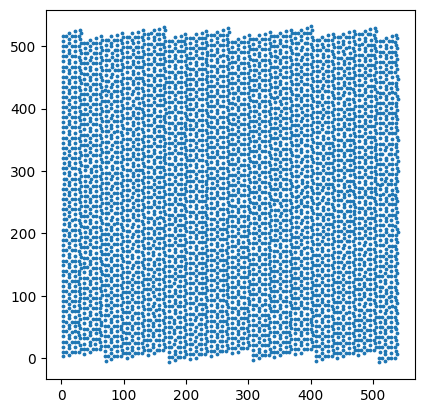

In [6]:
fig,ax = plt.subplots()
ax.scatter(df['x'],df['y'],3)
ax.set_aspect('1')


# Interplanar Spacing

In [7]:
# displacement_trhesold = 1
# # df_rot[df_rot['displacement']<displacement_trhesold].reset_index()
# df_f = df2[df2['x']>500].reset_index()
# fig,ax=plt.subplots()
# ax.scatter(df_f['x'],df_f['y'],3)
# ax.set_aspect(1)


In [8]:
df_rot = df

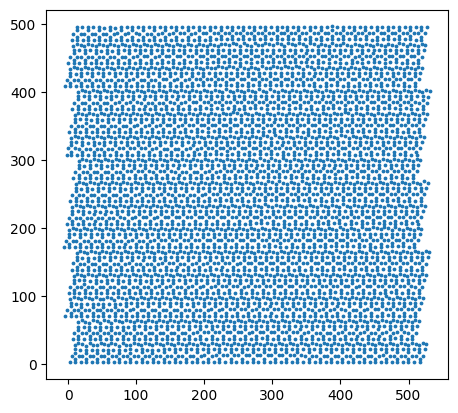

In [9]:
displacement_trhesold = 1
# df_rot[df_rot['displacement']<displacement_trhesold].reset_index()
df_f = df_rot[df_rot['x']<500].reset_index()
fig,ax=plt.subplots()
ax.scatter(df_f['y'],df_f['x'],3)
ax.set_aspect(1)


In [10]:
def get_interplanarSpacings(fixedPos,movingPos,df_rot,mu_c_direction='x',selected_motif='motif_1',max_distance_px=50,displacement_thresold = 1.5 ):
    

    # df_rot = df_rot[df_rot['displacement']<displacement_thresold].reset_index()
    # df_rot = df_rot[df_rot['y']<500].reset_index()
    df_rot_3a = df_rot[df_rot['label_mu'] ==fixedPos]
    selected_site = movingPos
    diff_vals = np.zeros((len(df_rot_3a), len(df_rot)))
    
    # print(df_rot_3a)
    # print(df_rot)
    ## calculate euclididan distance between respetive sites with label fixedPos and movingPos
    for i in range(0, len(df_rot["y"].values)):
        print(df_rot.at[i,'label_mu'])
        print(df_rot.at[i,"motif_source"])
        if df_rot.at[i,"label_mu"]==selected_site: # and df_rot.at[i,"motif_source"]==selected_motif:
            y_3a = df_rot_3a["y"].values
            x_3a = df_rot_3a["x"].values
    
            y = df_rot.at[i, "y"]
            x = df_rot.at[i, "x"]
    
            diff_vals[:,i] = np.sqrt((x_3a - x)**2 + (y_3a -y )**2)
        else:
            diff_vals[:,i] = np.inf

    print(diff_vals)
    min_dist_indices = np.argsort(np.abs(diff_vals), 1)
    # print(min_dist_indices.shape)
    # print(np.abs(diff_vals[min_dist_indices]))

    if movingPos == fixedPos:
        print('same site calculation')
        closest_distances = min_dist_indices[:, 2]
        second_closest_distance = min_dist_indices[:, 3]
    else:
        closest_distances = min_dist_indices[:, 0]
        second_closest_distance = min_dist_indices[:, 1]

    


    ## calculate distance in x or y dircetion
    min_distance_list = []
    df_rot_3a = df_rot_3a.reset_index()
    for i in range(0, len(min_dist_indices)):
        x1 = df_rot.at[closest_distances[i], mu_c_direction]
        x2 = df_rot.at[second_closest_distance[i], mu_c_direction]
        x_3a = df_rot_3a.at[i, mu_c_direction]
        min_distance_list.append(np.mean(np.abs([x_3a - x2, x_3a - x1])))
    
    min_distances = np.array(min_distance_list)
    min_distances = min_distances[min_distances<max_distance_px]
    return min_distances
    # plt.plot(min_distances)
    # min_distances.mean()

In [11]:
def get_interplanarSpacings_wplot(fixedPos,movingPos,df_rot,mu_c_direction='x',selected_motif='motif_1',max_distance_px=50,displacement_thresold = 1.5,plotting=False):
    print(movingPos)
    print(fixedPos)
    # if plotting:

    # df_rot = df_rot[df_rot['displacement']<displacement_thresold].reset_index()
    # df_rot = df_rot[df_rot['y']<500].reset_index()
    df_rot_3a = df_rot[df_rot['label_mu'] ==fixedPos]
    selected_site = movingPos
    diff_vals = np.zeros((len(df_rot_3a), len(df_rot)))
    
    # print(df_rot_3a)
    # print(df_rot)
    ## calculate euclididan distance between respetive sites with label fixedPos and movingPos
    for i in range(0, len(df_rot["y"].values)):
   
        if df_rot.at[i,"label_mu"]==selected_site: # and df_rot.at[i,"motif_source"]==selected_motif:
            # print(df_rot.at[i,'label_mu'])
        # print(df_rot.at[i,"motif_source"])
            y_3a = df_rot_3a["y"].values
            x_3a = df_rot_3a["x"].values
    
            y = df_rot.at[i, "y"]
            x = df_rot.at[i, "x"]
    
            diff_vals[:,i] = np.sqrt((x_3a - x)**2 + (y_3a -y )**2)
            # ax.scatter()
        else:
            diff_vals[:,i] = np.inf

    # print(diff_vals)

    min_dist_indices = np.argsort(np.abs(diff_vals), 1)
    # diff_vals = diff_vals[min_dist_indices]
    # print(min_dist_indices)
    # print(diff_vals[min_dist_indices])

    if movingPos == fixedPos:
        print('same site calculation')
        closest_distances = min_dist_indices[:, 2]
        second_closest_distance = min_dist_indices[:, 3]
    else:
        closest_distances = min_dist_indices[:, 0]
        second_closest_distance = min_dist_indices[:, 1]


    print(movingPos)
    print(fixedPos)


    cmap = mpl.colormaps['prism']
    colors = cmap(np.linspace(0, 1, len(min_dist_indices)))
    ## calculate distance in x or y dircetion
    min_distance_list = []
    print(len(df_rot))
    df_rot_3a = df_rot_3a.reset_index()
    print(closest_distances)

    unique_closest, counts_closest = np.unique(closest_distances, return_counts=True)
    unique_second, counts_second = np.unique(second_closest_distance, return_counts=True)
    
    # print(counts)
    if plotting:
        fig, ax = plt.subplots(figsize=(20,20))
        ax.scatter(df_rot.iloc[0:30]['x'],df_rot.iloc[0:30]['y'],color='gray')
    for i in range(1,len(min_dist_indices)):

        # print(second_closest_distance[i])
        # if any(counts_closest[unique_closest==closest_distances[i]]>1) or any(counts_second[unique_second==second_closest_distance[i]]>1):
        #     continue
        # print([second_closest_distance[i],closest_distances[i]])
        # print()
        x1 = df_rot.at[closest_distances[i], mu_c_direction]
        x2 = df_rot.at[second_closest_distance[i], mu_c_direction]
        x_3a = df_rot_3a.at[i, mu_c_direction]
        # print(closest_distances[i],second_closest_distance[i])

        # diff_c = diff_vals[closest_distances[i],0]
        # diff_sc = diff_vals[second_closest_distance[i],1]

        if np.abs([x_3a - x1])<max_distance_px and  plotting:
            if i==1:
                ax.scatter(df_rot.at[closest_distances[i], 'x'],df_rot.at[closest_distances[i], 'y'],color=colors[i],label=f"{movingPos}, 1st")
                ax.scatter(df_rot.at[second_closest_distance[i], 'x'],df_rot.at[second_closest_distance[i], 'y'],color=colors[i],marker='v',label=f"{movingPos}, 2nd")
                ax.scatter(df_rot_3a.at[i, 'x'], df_rot_3a.at[i, 'y'],color=colors[i],marker='s',label=f"{fixedPos}")
            elif i<30:
                ax.scatter(df_rot.at[closest_distances[i], 'x'],df_rot.at[closest_distances[i], 'y'],color=colors[i])
                ax.scatter(df_rot.at[second_closest_distance[i], 'x'],df_rot.at[second_closest_distance[i], 'y'],color=colors[i],marker='v')
                ax.scatter(df_rot_3a.at[i, 'x'], df_rot_3a.at[i, 'y'],color=colors[i],marker='s')
            if i <30:
                ax.text(df_rot_3a.at[i, 'x'], df_rot_3a.at[i, 'y'],i)
                ax.text(df_rot.at[closest_distances[i], 'x'],df_rot.at[closest_distances[i], 'y'],i)
                ax.text(df_rot.at[second_closest_distance[i], 'x'],df_rot.at[second_closest_distance[i], 'y'],i)
        # print(len(df_rot_3a.at[i,'x']))
        # min_distance_list.append(np.mean(np.abs([x_3a - x2, x_3a - x1])))
        if fixedPos=='3a':
            # min_distance_list.append(np.(np.abs([x_3a - x2, x_3a - x1])))
            min_distance_list.append((np.abs([x_3a - x1])))
            min_distance_list.append((np.abs([x_3a - x2])))
        else:
            min_distance_list.append(np.mean(np.abs([x_3a - x1])))
        # min_distance_list.append(np.mean(np.abs([x_3a - x2])))
   
        # if i>30:
        #     break
    if plotting:
        ax.legend()
        # ax.set_xlim(0,500)
        # ax.set_ylim(0,500)
        # print(closest_distances)
        ax.set_aspect(1)
    min_distances = np.array(min_distance_list)
    min_distances = min_distances[min_distances<max_distance_px]
    # ax.set_xlim(490,520)
    # ax.set_ylim()
    return min_distances
    # plt.plot(min_distances)
    # min_distances.mean()

In [12]:
df

,cell_i,cell_j,atom_id,label,x_pos,y_pos,x_old,y_old,x_unit,y_unit,x,y,label_mu
0,0,0,1,0,17.296412,10.303289,17.079554,9.773800,17.296412,10.303289,17.296412,10.303289,6c3
1,0,0,2,1,30.940569,15.147828,30.702505,14.968066,30.940569,15.147828,30.940569,15.147828,6c2
2,0,0,3,2,3.215953,2.916183,3.032670,1.951545,3.215953,2.916183,3.215953,2.916183,18h
3,0,0,4,3,7.522267,10.560128,7.302348,9.895997,7.522267,10.560128,7.522267,10.560128,6c3
4,0,0,5,4,21.666746,18.062788,21.412701,17.838331,21.666746,18.062788,21.666746,18.062788,18h
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5605,31,0,5606,6,12.657187,521.568481,13.589283,521.963135,11.995004,15.163363,12.657187,521.568481,6c1
5606,31,0,5607,7,27.920347,515.495300,29.015669,516.165894,27.258165,9.090160,27.920347,515.495300,6c2
5607,31,0,5608,8,29.439962,526.309387,30.568806,527.011108,28.777779,19.904268,29.439962,526.309387,3a
5608,31,0,5609,9,21.955389,515.834473,22.983845,516.396606,21.293205,9.429355,21.955389,515.834473,18h


In [13]:
# min_distances_m1_t

6c2
3a
6c2
3a
5610
[   1   40   62   95   45  128   67  106  161  183  111  122  117  172
  155  249  177  227  315  194  221  348  243  254  381  337  392  414
  309  320  370  342  353  364  502  386  397  408  419  568  441  491
  612  474  485  667  601  634  529  540  551  733  557  584  711  788
  700  777  639  678  661  672  854  832  876  755  727  722  749  760
  771  953  793  804 1008  826  887  848  859  870 1019  892  903 1140
  909  936  947  958  969  980  991 1002 1013 1024 1035 1046 1057 1068
 1079 1090 1101 1112 1123 1134 1107 1195 1167 1151 1189 1200 1211 1222
 1233 1244 1503 1266 1277 1288 1547 1310 1525 1332 1343 1338 1365 1624
 1360 1398 1409 1646 1679 1442 1393 1536 1475 1701 1497 1508 1519 1635
 1541 1591 1563 1574 1585 1800 1607 1618 1629 1855 1651 1723 1954 1684
 1695 1706 1778 1987 1739 1750 1712 1844 1783 1794 2020 2075 1888 1998
 2130 1860 1871 1943 1893 2108 1915 1926 1937 1948 1959 1970 2306 1992
 2003 2014 2251 2036 2119 2240 2328 2361 2317 2102 2284 24

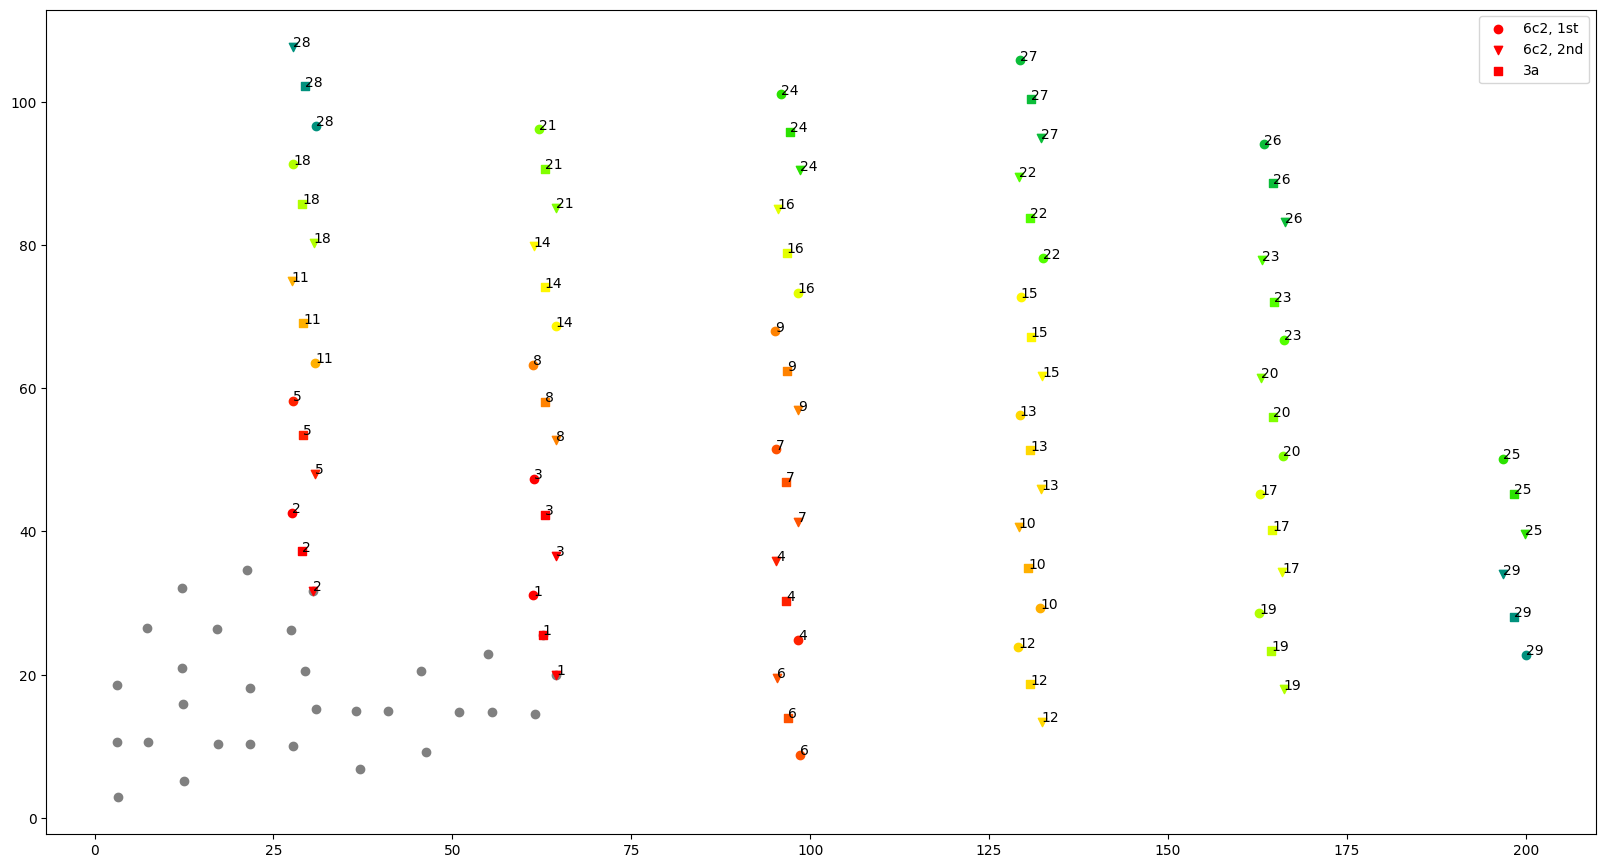

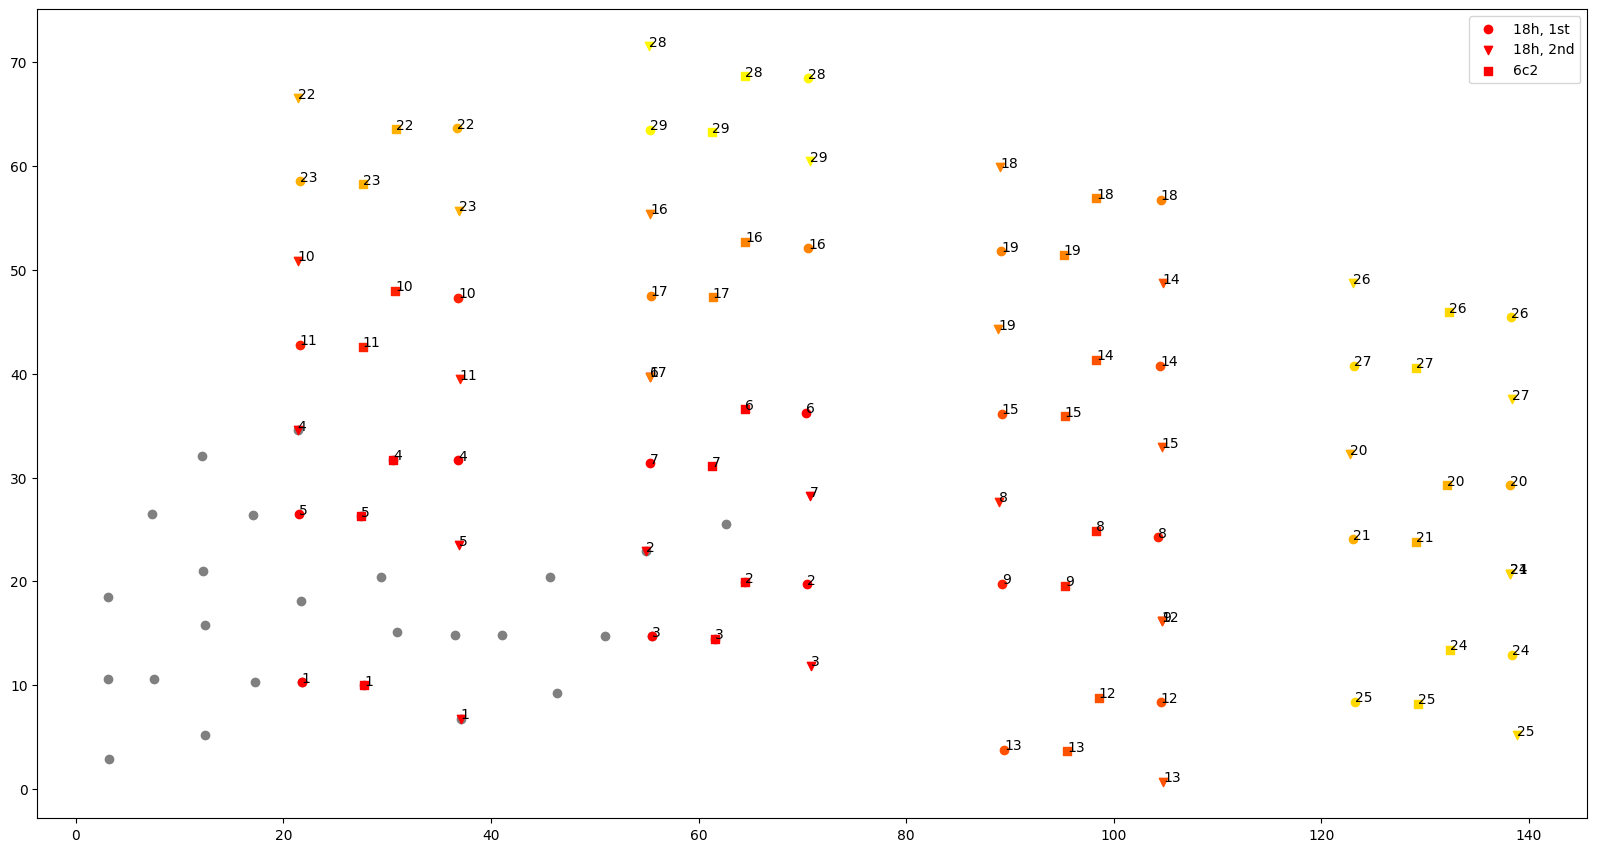

In [14]:
import matplotlib as mpl

fixed_site = '3a'
selected_site = '6c2'

min_distances_m1_t = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        # selected_motif='motif_1',
                                        max_distance_px=50,plotting=True)
min_distances_m2_t = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        selected_motif='motif_2',
                                        max_distance_px=50)



fixed_site = '6c2'
selected_site = '18h'
min_distances_m1_tK = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        # selected_motif='motif_1',
                                        max_distance_px=50,plotting=False,displacement_thresold = 1)
min_distances_m2_tK = get_interplanarSpacings_wplot(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        selected_motif='motif_2',
                                        max_distance_px=50,plotting=True)

min_distances_t = np.concatenate((min_distances_m1_t,min_distances_m2_t))
min_distances_tK = np.concatenate((min_distances_m1_tK,min_distances_m2_tK))


print(min_distances_t.mean() * md['nm_per_pixel']* 10, 'Å')
print(min_distances_t.std() * md['nm_per_pixel']* 10, 'Å')



## RWTH gpt becasue i am lazy
# Put them into a list for easy iteration
all_min_distances = [
    min_distances_t,
    min_distances_m1_t,
    # min_distances_m2_t,
    min_distances_tK,
    min_distances_m1_tK,
    # min_distances_m2_tK,
]


stats = []                     # each element will be (index, mean, std)
for idx, arr in enumerate(all_min_distances):
    mean_val = arr.mean()
    std_val  = np.std(arr, ddof=1)   # sample std‑deviation (ddof=1) – change to 0 for population
    stats.append((idx, mean_val, std_val))



array_names = ['d_t','d_t_m1','d_tK','d_tK_m1']

output_path = results_folder.joinpath("min_distances_stats.txt")
with open(output_path, "w") as f:
    # Header line (optional, but handy for readability)
    f.write("array_index,mean,standard_deviation\n")
    # One line per array
    for idx, mean_val, std_val in stats:
        f.write(f"{array_names[idx]},{mean_val* md['nm_per_pixel']* 10:.6f},{std_val* md['nm_per_pixel']* 10:.6f}\n")

print(f"Statistics saved to '{output_path}'.")

In [15]:
min_distances_t

array([1.35389709, 1.87042999, 1.3792057 , ..., 1.53771973, 1.56022263,
       1.51961517], shape=(2036,))

In [16]:
min_distances_m1_tK

array([6.02919769, 5.94810486, 6.13303757, ..., 6.02255249, 9.19058418,
       5.96495819], shape=(1019,))

In [17]:
# min_distances=np.concatenate((min_distances_m1,min_distances_m2))
# print(min_distances.mean() * md['nm_per_pixel']* 10, 'Å')
# print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')

Text(0.5, 1.0, 'Motif 2')

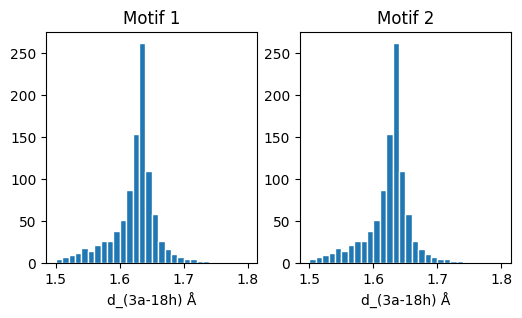

In [18]:
# Compare the distribution of dt_k values
fig,ax = plt.subplots(1,2,figsize=(6,3))
spacings = np.arange(1.5,1.8,0.01)
ax[0].hist(min_distances_m1_tK* md['nm_per_pixel']* 10 , spacings,edgecolor='white')
ax[1].hist(min_distances_m2_tK* md['nm_per_pixel']* 10,  spacings,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(3a-{selected_site}) Å")
ax[1].set_xlabel(f"d_(3a-{selected_site}) Å")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')
# ax[0].set_xlim(1.5,1.8)
# ax[1].set_xlim(1.5,1.8)

Text(0.5, 1.0, 'Motif 2')

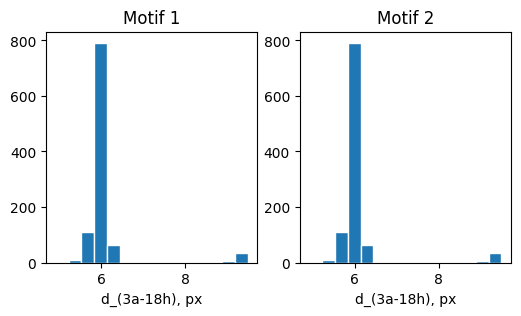

In [19]:
fig,ax = plt.subplots(1,2,figsize=(6,3))
ax[0].hist(min_distances_m1_tK , bins=15,edgecolor='white')
ax[1].hist(min_distances_m2_tK,  bins=15,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(3a-{selected_site}), px")
ax[1].set_xlabel(f"d_(3a-{selected_site}), px")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')


In [20]:
min_distances_m1_t* md['nm_per_pixel']

array([0.03662954, 0.05060428, 0.03731426, ..., 0.04160284, 0.04221166,
       0.04111303], shape=(1018,))

Text(0.5, 1.0, 'Motif 2')

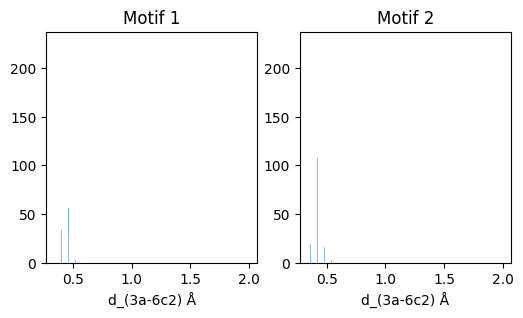

In [21]:
# Compare the distribution of dt_k values
fig,ax = plt.subplots(1,2,figsize=(6,3))
spacings = np.arange(0.35,2,0.01)
ax[0].hist(min_distances_m1_t* md['nm_per_pixel']* 10 , spacings,edgecolor='white')
ax[1].hist(min_distances_m2_t* md['nm_per_pixel']* 10,  spacings,edgecolor='white')#* md['nm_per_pixel']* 10
#print(min_distances.std() * md['nm_per_pixel']* 10, 'Å')
# min_distances
# plt.hist(
ax[0].set_xlabel(f"d_(3a-6c2) Å")
ax[1].set_xlabel(f"d_(3a-6c2) Å")
ax[0].set_title('Motif 1')
ax[1].set_title('Motif 2')
# ax[0].set_xlim(0.35,0.65)
# ax[1].set_xlim(0.35,0.65)

In [22]:
def get_interplanarSpacings_extended_filters(fixedPos,movingPos,df_rot,mu_c_direction='x',selected_motif='motif_1',max_distance_px=50,displacement_thresold = 1.5,max_dev_y=5 ):

    # df_rot = df_rot[df_rot['displacement']<displacement_thresold].reset_index()
    # df_rot = df_rot[df_rot['y']<500].reset_index()
    df_rot_3a = df_rot[df_rot['label_mu'] ==fixedPos]
    selected_site = movingPos
    diff_vals = np.zeros((len(df_rot_3a), len(df_rot)))
    diff_vals_y = np.zeros((len(df_rot_3a), len(df_rot)))
    diff_vals_x = np.zeros((len(df_rot_3a), len(df_rot)))
    
    # print(df_rot_3a)
    # print(df_rot)
    ## calculate euclididan distance between respetive sites with label fixedPos and movingPos
    for i in range(0, len(df_rot["y"].values)):
        print(df_rot.at[i,'label_mu'])
        print(df_rot.at[i,"motif_source"])
        if df_rot.at[i,"label_mu"]==selected_site:# and df_rot.at[i,"motif_source"]==selected_motif:
            y_3a = df_rot_3a["y"].values
            x_3a = df_rot_3a["x"].values
    
            y = df_rot.at[i, "y"]
            x = df_rot.at[i, "x"]
    
            diff_vals[:,i] = np.sqrt((x_3a - x)**2 + (y_3a -y )**2)
            diff_vals_y[:,i]  = np.abs((y_3a-y))
            diff_vals_x[:,i]  = np.abs((x_3a-x))
        else:
            diff_vals[:,i] = np.inf
            diff_vals_y[:,i]  =np.inf
            diff_vals_x[:,i]  =np.inf

    print(diff_vals)

    diff_vals = diff_vals[diff_vals_y<max_dev_y]
    diff_vals_x = diff_vals_x[diff_vals_y<max_dev_y]

    min_dist_indices = np.argsort(np.abs(diff_vals), 1)
    # print(min_dist_indices.shape)
    # print(np.abs(diff_vals[min_dist_indices]))

    if movingPos == fixedPos:
        print('same site calculation')
        
        closest_distances = min_dist_indices[:, 2]
        second_closest_distance = min_dist_indices[:, 3]
    else:
        closest_distances = min_dist_indices[:, 0]
        second_closest_distance = min_dist_indices[:, 1]

    ## calculate distance in x or y dircetion
    min_distance_list = []
    df_rot_3a = df_rot_3a.reset_index()
    for i in range(0, len(min_dist_indices)):
        x1 = diff_vals_x[closest_distances[i], mu_c_direction]
        x2 =diff_vals_x[second_closest_distance[i], mu_c_direction]
        # x_3a = df_rot_3a.at[i, mu_c_direction]
        min_distance_list.append(np.mean(x1,x2))
    
    min_distances = np.array(min_distance_list)
    min_distances = min_distances[min_distances<max_distance_px]
    return min_distances
    # plt.plot(min_distances)
    # min_distances.mean()

In [23]:
fixed_site = '3a'
selected_site = '3a'
min_distances = get_interplanarSpacings(fixed_site,
                                        selected_site,
                                        df_rot,mu_c_direction='x',
                                        selected_motif='motif_2',
                                        max_distance_px=50,
                                        displacement_thresold =3)

6c3


KeyError: 'motif_source'

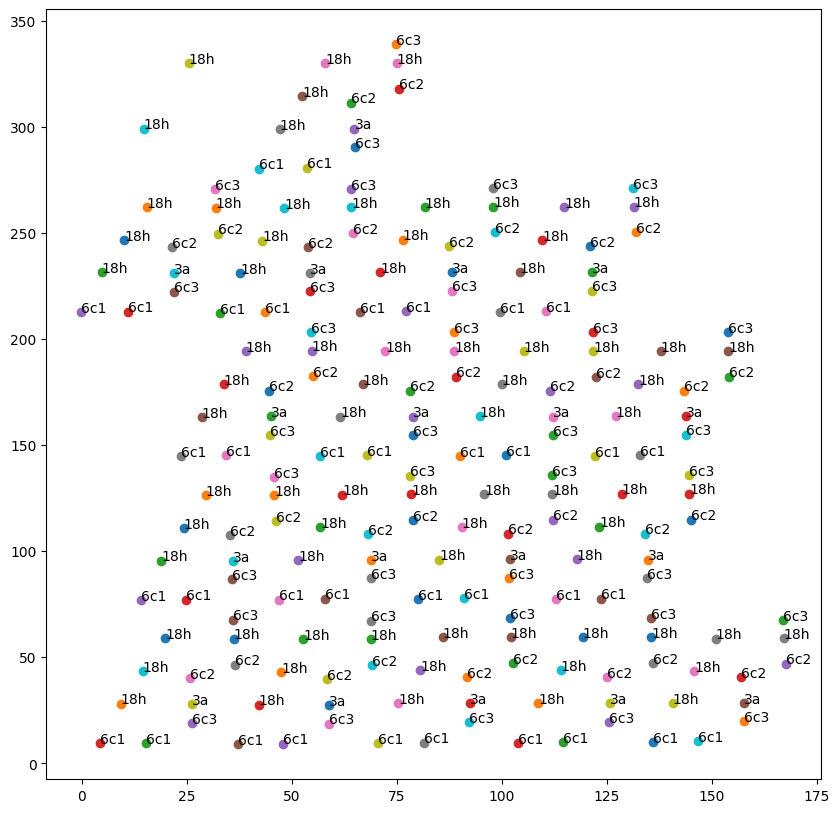

In [ ]:
fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,200):
    ax.scatter(df_rot.at[i,'y'].item(),df_rot.at[i,'x'].item())
    ax.text(df_rot.at[i,'y'].item(),df_rot.at[i,'x'].item(),str(df_rot.at[i,'label_mu']))#,str(i))

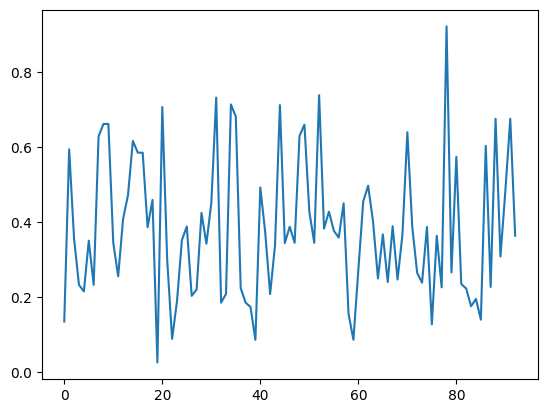

In [ ]:
plt.plot(min_distances)

## Debugging

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114


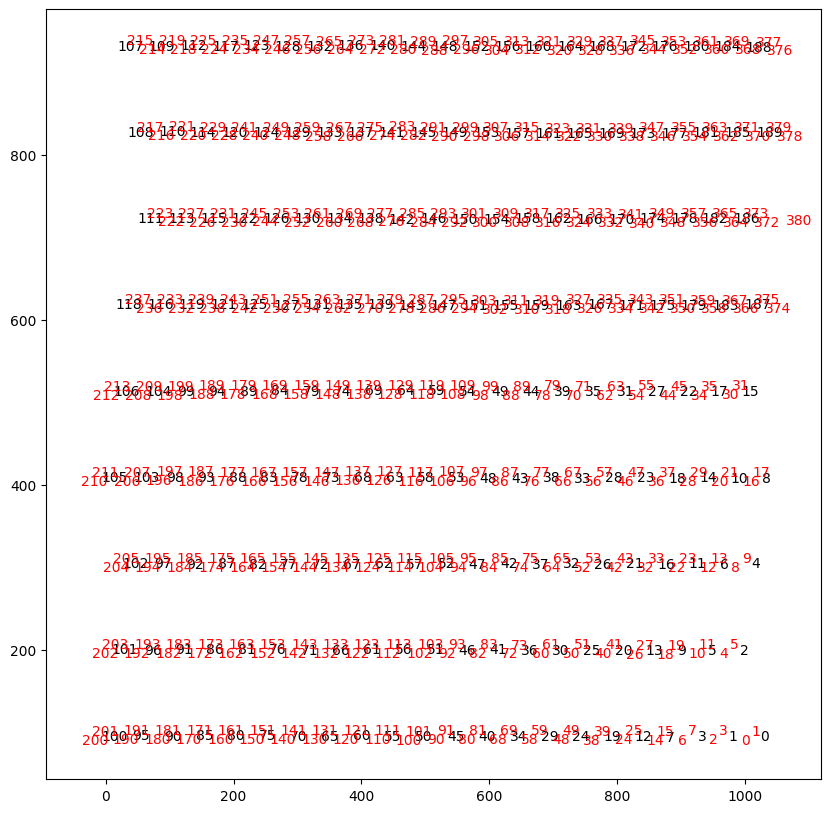

In [ ]:
df_rot_3a = df_rot[df_rot['label_mu']=='3a'].reset_index()
fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,len(df_rot_3a)-1):
    print(str(i))
    ax.plot(df_rot_3a.at[i,'y'].item(),df_rot_3a.at[i,'x'].item())
    ax.text(df_rot_3a.at[i,'y'].item(),df_rot_3a.at[i,'x'].item(),str(i))#,str(i))
df_rot_18h = df_rot[df_rot['label_mu']=='6c2'].reset_index()
# fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,len(df_rot_18h)-1):
    print(str(i))
    ax.plot(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item())
    ax.text(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item(),str(i),color='r')#,str(i))

In [ ]:
(df_rot_3a['x'].values[0]-df_rot_3a['x'].values[1])*3*md['nm_per_pixel']

np.float64(-0.005215187988361556)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

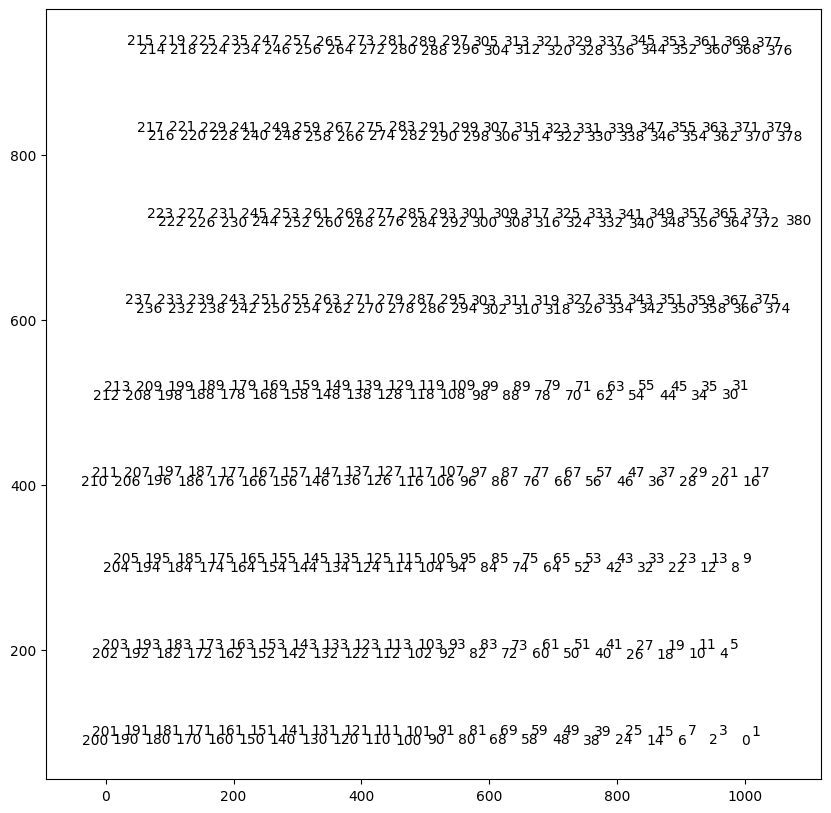

In [ ]:
df_rot_18h = df_rot[df_rot['label_mu']=='6c2'].reset_index()
fig,ax = plt.subplots(figsize=(10,10))
for i in range(0,len(df_rot_18h)-1):
    print(str(i))
    ax.plot(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item())
    ax.text(df_rot_18h.at[i,'y'].item(),df_rot_18h.at[i,'x'].item(),str(i))#,str(i))

In [ ]:
min_vals = np.nanmin(np.abs(diff_vals),1)
min_vals[[1,2,5,9,14,20,24,28,33,37,41,45,49]]


NameError: name 'diff_vals' is not defined